Saving DATASET.csv to DATASET (3).csv
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction Sta

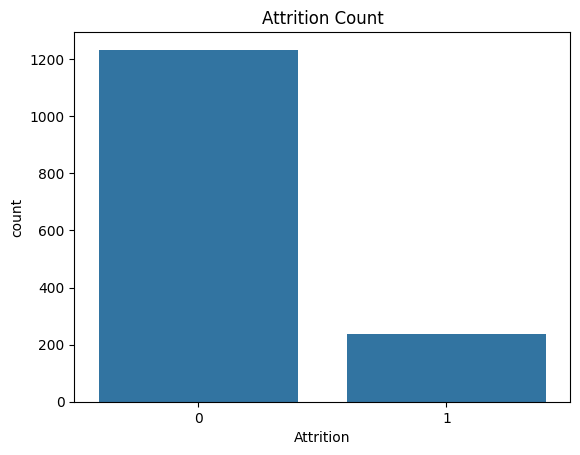

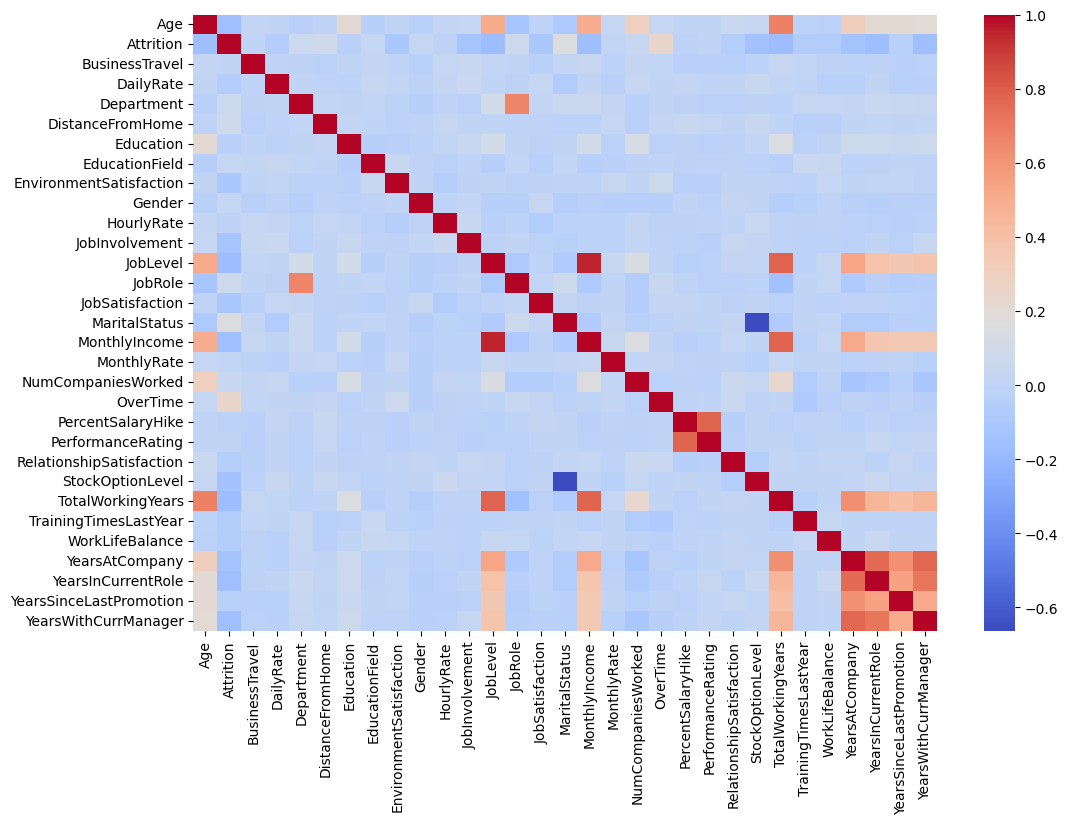

Before SMOTE
Attrition
0    986
1    190
Name: count, dtype: int64

After SMOTE
Attrition
0    986
1    986
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Accuracy : 74.49%
Decision Tree Accuracy : 75.17%
Random Forest Accuracy : 79.93%

Model Comparison


,Model,Accuracy (%)
2,Random Forest,79.931973
1,Decision Tree,75.170068
0,Logistic Regression,74.489796


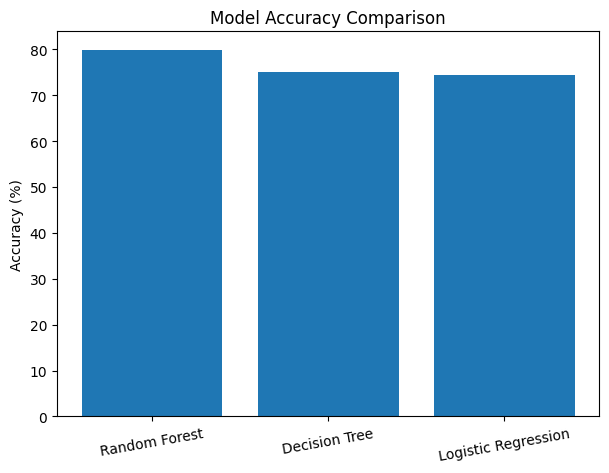


Best Model : Random Forest

Accuracy : 79.93 %

Classification Report

              precision    recall  f1-score   support

           0       0.87      0.90      0.88       247
           1       0.34      0.28      0.31        47

    accuracy                           0.80       294
   macro avg       0.60      0.59      0.59       294
weighted avg       0.78      0.80      0.79       294



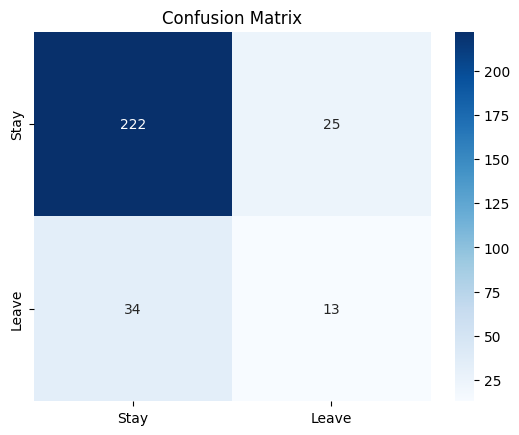


Top 10 Features


,Feature,Importance
22,StockOptionLevel,0.094592
13,JobSatisfaction,0.061494
15,MonthlyIncome,0.057616
7,EnvironmentSatisfaction,0.048258
0,Age,0.047371
10,JobInvolvement,0.045570
29,YearsWithCurrManager,0.045000
16,MonthlyRate,0.042801
23,TotalWorkingYears,0.041158
2,DailyRate,0.037878


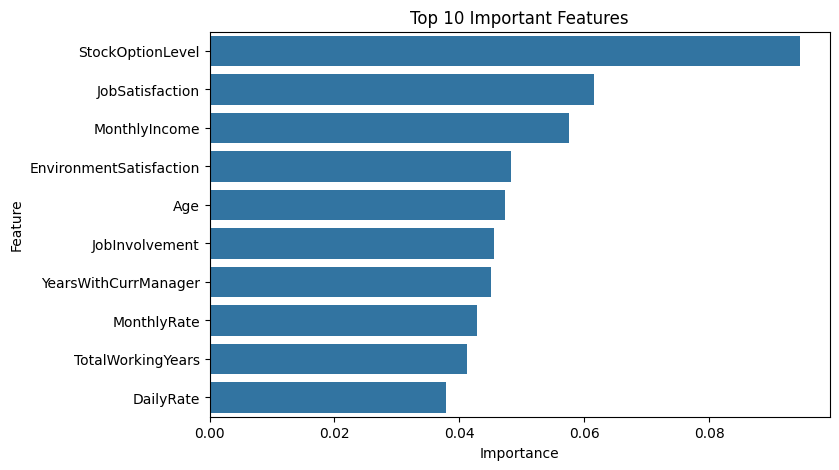

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Sample Prediction
Employee is Likely to Leave
Stay : 18.0 %
Leave : 82.0 %


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Actual,Predicted
0,41,2,1102,2,1,2,1,2,0,94,...,0,8,0,1,6,4,0,5,Leave,Leave
1,49,1,279,1,8,1,1,3,1,61,...,1,10,3,3,10,7,1,7,Stay,Stay
2,37,2,1373,1,2,2,4,4,1,92,...,0,7,3,3,0,0,0,0,Leave,Stay
3,33,1,1392,1,3,4,1,4,0,56,...,0,8,3,3,8,7,3,0,Stay,Leave
4,27,2,591,1,2,1,3,1,1,40,...,1,6,3,3,2,2,2,2,Stay,Stay
5,32,1,1005,1,2,2,1,4,1,79,...,0,8,2,2,7,7,3,6,Stay,Stay
6,59,2,1324,1,3,3,3,3,0,81,...,3,12,3,2,1,0,0,0,Stay,Stay
7,30,2,1358,1,24,1,1,4,1,67,...,1,1,2,3,1,0,0,0,Stay,Stay
8,38,1,216,1,23,3,1,4,1,44,...,0,10,2,3,9,7,1,8,Stay,Stay
9,36,2,1299,1,27,3,3,3,1,94,...,2,17,3,2,7,7,7,7,Stay,Stay


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT COMPLETED SUCCESSFULLY


In [4]:
# ==========================================================
# EMPLOYEE ATTRITION PREDICTION - SINGLE PROGRAM
# ==========================================================

# Install SMOTE (Colab)
!pip install -q imbalanced-learn

# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

# ---------------- Upload Dataset ----------------
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

print(df.head())
print(df.shape)

# ---------------- Preprocessing ----------------
df.drop(columns=['EmployeeCount','EmployeeNumber','Over18','StandardHours'], inplace=True)

df['Attrition'] = df['Attrition'].map({'Yes':1,'No':0})

le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

X = df.drop('Attrition', axis=1)
y = df['Attrition']

# ---------------- EDA ----------------
sns.countplot(x=y)
plt.title("Attrition Count")
plt.show()

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.show()

# ---------------- Train-Test Split ----------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# ---------------- SMOTE ----------------
print("Before SMOTE")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

print("\nAfter SMOTE")
print(y_train.value_counts())

# ---------------- Models ----------------
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42)
}

accuracy = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    accuracy[name] = accuracy_score(y_test, pred)
    print(f"{name} Accuracy : {accuracy[name]*100:.2f}%")

# ---------------- Comparison ----------------
comparison = pd.DataFrame({
    "Model": accuracy.keys(),
    "Accuracy (%)":[i*100 for i in accuracy.values()]
}).sort_values("Accuracy (%)", ascending=False)

print("\nModel Comparison")
display(comparison)

plt.figure(figsize=(7,5))
plt.bar(comparison["Model"], comparison["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=10)
plt.show()

# ---------------- Best Model ----------------
best_model = comparison.iloc[0]["Model"]
print("\nBest Model :", best_model)

model = models[best_model]

# ---------------- Evaluation ----------------
pred = model.predict(X_test)

print("\nAccuracy :", round(accuracy_score(y_test,pred)*100,2),"%")
print("\nClassification Report\n")
print(classification_report(y_test,pred))

cm = confusion_matrix(y_test,pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay","Leave"],
    yticklabels=["Stay","Leave"]
)
plt.title("Confusion Matrix")
plt.show()

# ---------------- Feature Importance ----------------
if hasattr(model, "feature_importances_"):
    importance = pd.DataFrame({
        "Feature": X.columns,
        "Importance": model.feature_importances_
    }).sort_values("Importance", ascending=False)

    print("\nTop 10 Features")
    display(importance.head(10))

    plt.figure(figsize=(8,5))
    sns.barplot(
        data=importance.head(10),
        x="Importance",
        y="Feature"
    )
    plt.title("Top 10 Important Features")
    plt.show()

# ---------------- Save Model ----------------
joblib.dump(model,"attrition_model.pkl")
files.download("attrition_model.pkl")

# ---------------- Sample Prediction ----------------
sample = X.iloc[[0]]

prediction = model.predict(sample)
prob = model.predict_proba(sample)

print("\nSample Prediction")
print("Employee is Likely to Leave" if prediction[0] else "Employee is Likely to Stay")

print("Stay :", round(prob[0][0]*100,2),"%")
print("Leave :", round(prob[0][1]*100,2),"%")

# ---------------- First 10 Predictions ----------------
result = X.head(10).copy()

result["Actual"] = y.head(10).map({0:"Stay",1:"Leave"}).values
result["Predicted"] = pd.Series(model.predict(X.head(10))).map({0:"Stay",1:"Leave"})

display(result)

result.to_csv("Prediction_Result.csv",index=False)
files.download("Prediction_Result.csv")

print("\nPROJECT COMPLETED SUCCESSFULLY")
